# QVHighlights — Data Collection & Preparation
## Stage 0: Dataset for M1 (Moment Retrieval) and M2 (Thumbnail → Query)

**Rubric alignment:**
- Problem Understanding (15%) - we explicitly reason about data structure choices
- Implementation Quality (15%) - clean, modular, reproducible pipeline
- Experimentation (15%) - justified subset strategy with clear reasoning

---

### What this notebook does
1. Mounts Drive and sets up the project directory
2. Clones the moment_detr repo (annotations included)
3. Parses and explains every field in the JSONL annotation format
4. Groups segments by original YouTube video
5. Builds unified processed dataset for M1 and M2
6. Downloads a subset of raw video clips (for M2 frame extraction)
7. Extracts frames from downloaded clips
8. Constructs `(frame_image, query)` training pairs for M2
9. Saves final processed splits to Drive

**Design decisions are documented inline with explicit reasoning.**

# 1. Environment Setup & Drive Mount

In [ ]:
# Install required packages
!pip install -q yt-dlp opencv-python-headless Pillow tqdm
!pip install -q git+https://github.com/openai/CLIP.git

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 182.3/182.3 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 15.4 MB/s eta 0:00:00


In [ ]:
import os, json, random, subprocess, shutil
from pathlib import Path
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
from PIL import Image
from tqdm import tqdm

# ── Mount Drive ──────────────────────────────────────────────────────────────
from google.colab import drive
drive.mount('/content/drive')

# ── Project root on Drive ────────────────────────────────────────────────────
PROJECT_ROOT = Path("/content/drive/MyDrive/thumbnail_project")
REPO_DIR     = PROJECT_ROOT / "moment_detr"          # cloned repo
DATA_DIR     = REPO_DIR / "data"                      # JSONL annotations (already in repo)
VIDEO_DIR    = PROJECT_ROOT / "qvh_videos"            # downloaded .mp4 clips
FRAMES_DIR   = PROJECT_ROOT / "qvh_frames"            # extracted frames
PROCESSED_DIR= PROJECT_ROOT / "processed"             # final dataset files

for d in [PROJECT_ROOT, VIDEO_DIR, FRAMES_DIR, PROCESSED_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("All directories created.")

Mounted at /content/drive
Project root: /content/drive/MyDrive/thumbnail_project
All directories created.


# ⚠️ RESET CELL — Run this ONLY when starting fresh
Delete all previously generated outputs: extracted frames, processed JSONL files,
and visualisation PNGs. Videos are preserved (expensive to re-download).

**Skip this cell if you are resuming a previous run.**


In [ ]:
# ── FULL RESET — deletes all generated outputs, keeps downloaded videos ──────
# Set CONFIRM = True to actually run the deletion.
CONFIRM = False   # ← change to True when you want to reset

if not CONFIRM:
    print("Reset skipped. Set CONFIRM = True to delete outputs.")
else:
    import shutil, os
    deleted = {"frames": 0, "processed": 0, "pngs": 0}

    # 1. Delete all extracted frames (.jpg)
    if FRAMES_DIR.exists():
        for f in FRAMES_DIR.glob("*.jpg"):
            f.unlink()
            deleted["frames"] += 1
        print(f"  Deleted {deleted['frames']} frames from {FRAMES_DIR}")

    # 2. Delete processed JSONL files
    if PROCESSED_DIR.exists():
        for f in PROCESSED_DIR.glob("*.jsonl"):
            f.unlink()
            deleted["processed"] += 1
        for f in PROCESSED_DIR.glob("*.json"):
            f.unlink()
            deleted["processed"] += 1
        print(f"  Deleted {deleted['processed']} processed files from {PROCESSED_DIR}")

    # 3. Delete visualisation PNGs
    if PROCESSED_DIR.exists():
        for f in PROCESSED_DIR.glob("*.png"):
            f.unlink()
            deleted["pngs"] += 1
        print(f"  Deleted {deleted['pngs']} PNG visualisations")

    print(f"\n✓ Reset complete. Videos in {VIDEO_DIR} are untouched.")
    print("You can now run the notebook from the beginning.")


# 2. Clone moment_detr Repository

The annotations (JSONL files) are included in the repo under `data/`.
No separate download is needed for the annotation files.

In [ ]:
if not (REPO_DIR / "data" / "highlight_train_release.jsonl").exists():
    print("Cloning moment_detr repo...")
    subprocess.run(
        ["git", "clone", "https://github.com/jayleicn/moment_detr.git", str(REPO_DIR)],
        check=True
    )
    print("Clone complete.")
else:
    print("Repo already cloned. Skipping.")

# Verify annotation files exist
for split in ["train", "val", "test"]:
    path = DATA_DIR / f"highlight_{split}_release.jsonl"
    exists = "✓" if path.exists() else "✗ MISSING"
    print(f"  {exists}  {path.name}")

Repo already cloned. Skipping.
  ✓  highlight_train_release.jsonl
  ✓  highlight_val_release.jsonl
  ✓  highlight_test_release.jsonl


# 3. Parse Annotation Files — Field-by-Field Explanation

Each line in the JSONL file is one `(video_segment, query)` pair.

| Field | Type | Meaning |
|---|---|---|
| `qid` | int | Unique query ID across the entire dataset |
| `query` | str | Human-written natural language description of a visual moment |
| `duration` | int | Length of the video segment in seconds (always ~150s) |
| `vid` | str | `{youtube_id}_{start_sec}_{end_sec}` — identifies which YouTube video AND which 150s segment |
| `relevant_windows` | list[list] | `[[start, end], ...]` — timestamps within the 150s segment where the query is answered |
| `relevant_clip_ids` | list[int] | Indices of 2-second clips (clip 0 = seconds 0–2, clip 1 = seconds 2–4, ...) |
| `saliency_scores` | list[list] | One sublist per `relevant_clip_id`. Each sublist = `[score_annotator1, score_annotator2, score_annotator3]`. Score 4 = Very Good, 0 = Very Bad |

**Key insight for M2:** The clip with the highest mean saliency score is the best visual representative of the query — this is our training frame for the thumbnail-to-query model.

In [ ]:
def load_jsonl(path):
    """Load a JSONL file into a list of dicts."""
    records = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if line:
                records.append(json.loads(line))
    return records

# Load all three splits
train_raw = load_jsonl(DATA_DIR / "highlight_train_release.jsonl")
val_raw   = load_jsonl(DATA_DIR / "highlight_val_release.jsonl")
test_raw  = load_jsonl(DATA_DIR / "highlight_test_release.jsonl")

print(f"Train samples : {len(train_raw):,}")
print(f"Val samples   : {len(val_raw):,}")
print(f"Test samples  : {len(test_raw):,}")
print(f"Total         : {len(train_raw)+len(val_raw)+len(test_raw):,}")

Train samples : 7,218
Val samples   : 1,550
Test samples  : 1,542
Total         : 10,310


In [ ]:
import cv2
import numpy as np

def laplacian_sharpness(frame_path: str) -> float:
    """
    Estimate image sharpness via Laplacian variance.
    Higher = sharper. Used as a tiebreaker when annotator agreement is equal.
    Operates in grayscale to avoid colour channel noise.
    """
    img = cv2.imread(frame_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return 0.0
    return float(cv2.Laplacian(img, cv2.CV_64F).var())


def select_best_frame(relevant_clip_ids, saliency_scores,
                       relevant_windows=None, frame_paths=None):
    """
    Select the single best clip for M2 training using a principled
    tie-breaking hierarchy:

      L1  — highest mean saliency (unique winner).
      L2  — lowest variance across annotators (highest agreement).
      L3a — highest Laplacian sharpness, if frame_paths are available.
      L3b — latest clip id (climactic / peak position), otherwise.

    Args:
        relevant_clip_ids : list[int]   clip indices for this query
        saliency_scores   : list[list]  shape (n_clips, 3), scores 0-4
        relevant_windows  : unused, kept for interface compatibility
        frame_paths       : list[str] | None  paths aligned with relevant_clip_ids

    Returns:
        best_clip_id      : int
        best_timestamp    : float  (centre of the 2-second clip, in seconds)
        selection_reason  : str    (audit trail for the tiebreaker taken)
    """
    n = len(relevant_clip_ids)
    assert n == len(saliency_scores), "clip_ids and saliency_scores must have equal length"

    mean_scores = [sum(s) / len(s) for s in saliency_scores]
    max_score   = max(mean_scores)
    tied        = [i for i, s in enumerate(mean_scores) if s == max_score]

    # L1: unique maximum
    if len(tied) == 1:
        best_local = tied[0]
        reason = "unique_max"

    else:
        # L2: lowest annotator variance (highest agreement)
        variances = [
            sum((x - mean_scores[i]) ** 2 for x in saliency_scores[i]) / len(saliency_scores[i])
            for i in tied
        ]
        min_var = min(variances)
        agreed  = [tied[j] for j, v in enumerate(variances) if v == min_var]

        if len(agreed) == 1:
            best_local = agreed[0]
            reason = "annotator_agreement"

        else:
            # L3a: sharpest frame (needs pre-extracted frames)
            if frame_paths is not None:
                sharp = [laplacian_sharpness(frame_paths[i]) for i in agreed]
                best_local = agreed[int(np.argmax(sharp))]
                reason = "sharpness"
            else:
                # L3b: latest clip (climactic position)
                best_local = max(agreed, key=lambda i: relevant_clip_ids[i])
                reason = "temporal_position"

    best_clip_id   = relevant_clip_ids[best_local]
    best_timestamp = best_clip_id * 2 + 1  # centre of the 2-second clip
    return best_clip_id, best_timestamp, reason

# ── CLIP semantic frame ranking ───────────────────────────────────────────────
import threading
import torch
import clip as _clip_lib

_clip_model      = None
_clip_preprocess = None
_clip_device     = None
_clip_lock       = threading.Lock()   # serialise GPU calls across threads


def _get_clip():
    """Lazy-load CLIP ViT-B/32 once; reuse across all extract_frame calls."""
    global _clip_model, _clip_preprocess, _clip_device
    if _clip_model is None:
        _clip_device = "cuda" if torch.cuda.is_available() else "cpu"
        _clip_model, _clip_preprocess = _clip_lib.load("ViT-B/32", device=_clip_device)
        _clip_model.eval()
        print(f"CLIP ViT-B/32 loaded on {_clip_device}")
    return _clip_model, _clip_preprocess, _clip_device


def clip_rank_frames(frames_pil, query, model, preprocess, device):
    """
    Cosine similarity between each PIL frame and a text query under CLIP.

    Args:
        frames_pil : list[PIL.Image]
        query      : str
        model/preprocess/device: from _get_clip()

    Returns:
        np.ndarray of shape (N,) — cosine similarity in [-1, 1]
    """
    if not frames_pil:
        return np.array([])

    text_tok    = _clip_lib.tokenize([query], truncate=True).to(device)
    img_tensors = torch.stack([preprocess(f) for f in frames_pil]).to(device)

    with torch.no_grad():
        img_feats = model.encode_image(img_tensors)
        txt_feat  = model.encode_text(text_tok)
        img_feats = img_feats / img_feats.norm(dim=-1, keepdim=True)
        txt_feat  = txt_feat  / txt_feat.norm(dim=-1, keepdim=True)
        scores    = (img_feats @ txt_feat.T).squeeze(-1).cpu().numpy()

    return scores if scores.ndim > 0 else np.array([float(scores)])


In [ ]:
# ── Annotated example — print and explain one training record ────────────────
sample = train_raw[0]
print("=== RAW ANNOTATION RECORD ===")
print(json.dumps(sample, indent=2))

print("\n=== FIELD BREAKDOWN ===")
print(f"  qid            : {sample['qid']} — unique query identifier")
print(f"  vid            : {sample['vid']}")

# Parse vid into components
parts = sample["vid"].rsplit("_", 2)
yt_id, seg_start, seg_end = parts[0], float(parts[1]), float(parts[2])
print(f"    youtube_id   : {yt_id}")
print(f"    seg_start    : {seg_start}s  (where this 150s segment starts in the full video)")
print(f"    seg_end      : {seg_end}s")
print(f"    YouTube URL  : https://www.youtube.com/watch?v={yt_id}&t={int(seg_start)}")

print(f"  query          : \"{sample['query']}\"")
print(f"  duration       : {sample['duration']}s  (length of this segment)")
print(f"  relevant_windows: {sample['relevant_windows']}  (seconds within the 150s segment)")
print(f"  size of relevant_windows:{len(sample['relevant_windows'])} ")
print(f"  relevant_clip_ids: {sample['relevant_clip_ids']}  (2-sec clip indices)")
print(f"  size of relevent_clip_ids: {len(sample['relevant_clip_ids'])} ")
print(f"\n  saliency_scores: {sample['saliency_scores']}")
print(f"  size of saliency_scores: {len(sample['saliency_scores'])} ")
print(f"    → {len(sample['saliency_scores'])} clips × 3 annotators each")
mean_scores = [sum(s) / 3 for s in sample["saliency_scores"]]
best_clip_id, best_timestamp, selection_reason = select_best_frame(
    relevant_clip_ids=sample["relevant_clip_ids"],
    saliency_scores=sample["saliency_scores"],
)
print(f"    → mean scores per clip : {[round(s,2) for s in mean_scores]}")
print(f"    → best clip id         : {best_clip_id} (selection: {selection_reason})")
print(f"    → best frame timestamp : {best_timestamp}s  ← this is the M2 training frame")

# 4. Design Decisions

## 4.1 Use official JSONL as-is or create a processed version?

**Decision: Create a processed version.**

Reasons:
- The official JSONL has fields we do not need (raw saliency_scores as nested lists)
- We need to add derived fields: `youtube_id`, `seg_start`, `seg_end`, `best_clip_id`, `best_frame_timestamp`, `mean_saliency`
- We need to track which samples have downloaded video frames (for M2)
- A processed version with a clear schema makes the training code cleaner and less error-prone

We keep the original JSONL untouched and write new files: `train_processed.jsonl`, `val_processed.jsonl`, `test_processed.jsonl`

---

## 4.2 How to group segments from the same original YouTube video?

Each `vid` is `{youtube_id}_{start}_{end}`. The same YouTube video can appear multiple times with different start/end windows and different queries. For M1 training, this is fine — each segment is independent. For analysis, grouping by `youtube_id` lets us understand how many unique source videos we have.

---

## 4.3 Subset size — is 2000–2500 training samples reasonable?

**Decision: Yes, use 2000 training + full val + full test.**

Justification:
- The full train set has ~7,000 samples. Training M1 (Moment-DETR) on the full set takes ~12 hours on RTX 2080Ti. On Colab T4, that is 20–30 hours — too slow for iterative experimentation.
- 2000 samples = ~28% of train. The paper shows Moment-DETR with 5.4K in-domain pretraining videos achieves strong results. At 2000 we expect measurable performance with reasonable training time (~6–8 hours on T4).
- We use the official val and test splits without modification to ensure our metrics are comparable to the paper's reported numbers.
- We sample from train by **YouTube channel diversity** — not random — to avoid having multiple segments from the same video dominate the subset.

**Split strategy: stratified by video category (daily vlog / travel vlog / news) to match the full dataset's distribution.**

# 5. Build Processed Dataset

In [ ]:
def process_record(item, has_saliency=True):
  """
  Convert a raw annotation record into our unified processed format.

  Fields added:
  youtube_id       — extracted from vid
  seg_start/end    — the 150s window in the original YouTube video
  best_clip_id     — clip with highest mean saliency (for M2 frame)
  best_timestamp   — center of best clip in seconds (within the 150s segment)
  mean_saliency    — highest mean saliency score (quality indicator)
  frame_path       — where we will store the extracted frame (set later)
  video_downloaded — whether the clip has been downloaded
  """
  vid = item["vid"]
  parts = vid.rsplit("_", 2)
  yt_id     = parts[0]
  seg_start = float(parts[1])
  seg_end   = float(parts[2])

  processed = {
      "qid"              : item["qid"],
      "query"            : item["query"],
      "duration"         : item["duration"],
      "vid"              : vid,
      "youtube_id"       : yt_id,
      "seg_start"        : seg_start,
      "seg_end"          : seg_end,
      "relevant_windows" : item.get("relevant_windows", []),
      "relevant_clip_ids": item.get("relevant_clip_ids", []),
      "video_downloaded" : False,
      "frame_path"       : None,
  }

  # Derive best frame info from saliency (only available in train/val)
  if has_saliency and item.get("saliency_scores") and item.get("relevant_clip_ids"):
      scores   = item["saliency_scores"]
      clip_ids = item["relevant_clip_ids"]
      best_clip_id, best_ts, _ = select_best_frame(
          relevant_clip_ids=clip_ids,
          saliency_scores=scores,
      )
      mean_scores = [sum(s) / 3 for s in scores]
      processed["best_clip_id"]    = best_clip_id
      processed["best_timestamp"]  = best_ts
      processed["mean_saliency"]   = round(max(mean_scores), 3)
  else:
      processed["best_clip_id"]    = None
      processed["best_timestamp"]  = None
      processed["mean_saliency"]   = None

  return processed

# Process all splits
train_proc = [process_record(r, has_saliency=True)  for r in train_raw]
val_proc   = [process_record(r, has_saliency=True)  for r in val_raw]
test_proc  = [process_record(r, has_saliency=False) for r in test_raw]

print(f"Processed — train: {len(train_proc)}, val: {len(val_proc)}, test: {len(test_proc)}")
print("\nSample processed record:")
print(json.dumps(train_proc[0], indent=2))

# 6. Subset Selection — Stratified by Category

In [ ]:
# ── Infer category from query vocabulary ────────────────────────────────────
# QVHighlights has 3 categories: daily_vlog (~46%), travel_vlog (~43%), news (~11%)
# We infer category from query keywords as a simple proxy.

TRAVEL_KEYWORDS = {"beach","hotel","tour","plane","swim","visit","travel","ocean",
                "mountain","temple","city","airport","restaurant","street","market"}

NEWS_KEYWORDS   = {"protest","police","report","interview","press","fire","flood",
                "hurricane","crowd","rally","march","officer","military"}

def infer_category(query):
    words = set(query.lower().split())
    if words & NEWS_KEYWORDS:
        return "news"
    if words & TRAVEL_KEYWORDS:
        return "travel_vlog"
    return "daily_vlog"

for r in train_proc:
    r["category"] = infer_category(r["query"])

from collections import Counter
cat_counts = Counter(r["category"] for r in train_proc)
print("Category distribution in full train set:")
for cat, cnt in sorted(cat_counts.items()):
    print(f"  {cat:15s}: {cnt:5d}  ({cnt/len(train_proc)*100:.1f}%)")

Category distribution in full train set:
  daily_vlog     :  6360  (88.1%)
  news           :   188  (2.6%)
  travel_vlog    :   670  (9.3%)


In [ ]:
# ── Stratified subset: 2000 samples matching category proportions ────────────
SUBSET_SIZE = 2000
random.seed(42)  # reproducibility

by_cat = defaultdict(list)
for r in train_proc:
    by_cat[r["category"]].append(r)

subset = []
for cat, records in by_cat.items():
    proportion = len(records) / len(train_proc)
    n = round(SUBSET_SIZE * proportion)
    sampled = random.sample(records, min(n, len(records)))
    subset.append((cat, sampled))
    print(f"  {cat:15s}: {len(sampled):4d} samples ({proportion*100:.1f}%)")

train_subset = []
for _, s in subset:
    train_subset.extend(s)

# Shuffle to mix categories
random.shuffle(train_subset)
print(f"\nFinal subset size: {len(train_subset)}")
print(f"Val size (full): {len(val_proc)}")
print(f"Test size (full): {len(test_proc)}")

  news           :   52 samples (2.6%)
  daily_vlog     : 1762 samples (88.1%)
  travel_vlog    :  186 samples (9.3%)

Final subset size: 2000
Val size (full): 1550
Test size (full): 1542


# 7. Save Processed Splits

In [ ]:
def save_jsonl(records, path):
    with open(path, "w") as f:
        for r in records:
            f.write(json.dumps(r) + "\n")
    print(f"Saved {len(records):,} records → {path}")

save_jsonl(train_subset, PROCESSED_DIR / "train_processed.jsonl")
save_jsonl(val_proc,     PROCESSED_DIR / "val_processed.jsonl")
save_jsonl(test_proc,    PROCESSED_DIR / "test_processed.jsonl")

# Also save the full train for reference
save_jsonl(train_proc,   PROCESSED_DIR / "train_full_processed.jsonl")

print("\nProcessed files saved to Drive.")

Saved 2,000 records → /content/drive/MyDrive/thumbnail_project/processed/train_processed.jsonl
Saved 1,550 records → /content/drive/MyDrive/thumbnail_project/processed/val_processed.jsonl
Saved 1,542 records → /content/drive/MyDrive/thumbnail_project/processed/test_processed.jsonl
Saved 7,218 records → /content/drive/MyDrive/thumbnail_project/processed/train_full_processed.jsonl

Processed files saved to Drive.


# 8. Download Video Clips for M2 Training

We download only the 150-second segment per video, not the full YouTube video.
Using `--download-sections` in yt-dlp limits each download to the exact window.

**Resolution: 480p** — sufficient for frame extraction, reduces storage ~4× vs 1080p.

**Estimated storage:** ~30–50 MB per clip × 2000 clips ≈ 60–100 GB total.
For a first run, we download the subset (2000 clips).
If storage is limited, use the `MAX_DOWNLOADS` parameter to start with fewer.

In [ ]:
# ── CONFIG ──────────────────────────────────────────────────────────────────
MAX_DOWNLOADS   = 2000  # set lower (e.g. 200) for a quick test run
PARALLEL_WORKERS = 6     # parallel yt-dlp processes

def download_clip(record):
    """Download a single 150-second video segment using yt-dlp."""
    vid      = record["vid"]
    yt_id    = record["youtube_id"]
    start    = record["seg_start"]
    end      = record["seg_end"]
    out_path = VIDEO_DIR / f"{vid}.mp4"

    if out_path.exists() and out_path.stat().st_size > 10_000:
        return {"vid": vid, "status": "skip", "path": str(out_path)}

    url = f"https://www.youtube.com/watch?v={yt_id}"
    cmd = [
        "yt-dlp",
        "--download-sections", f"*{start}-{end}",
        "--format", "bestvideo[height<=480][ext=mp4]+bestaudio[ext=m4a]/best[height<=480]",
        "--merge-output-format", "mp4",
        "--extractor-args", "youtube:player_client=android",
        "--quiet", "--no-warnings",
        "-o", str(out_path),
        url
    ]
    try:
        subprocess.run(cmd, timeout=180, check=True,
                    capture_output=True)
        return {"vid": vid, "status": "ok", "path": str(out_path)}
    except subprocess.TimeoutExpired:
        return {"vid": vid, "status": "timeout", "path": None}
    except subprocess.CalledProcessError:
        return {"vid": vid, "status": "fail", "path": None}

print(f"Downloading up to {MAX_DOWNLOADS} clips with {PARALLEL_WORKERS} workers...")
print("This will take several hours. Monitor progress below.")
print("You can interrupt and resume — already-downloaded clips are skipped.\n")

to_download = train_subset[:MAX_DOWNLOADS]
results = {"ok": 0, "skip": 0, "fail": 0, "timeout": 0}
download_log = []

with ThreadPoolExecutor(max_workers=PARALLEL_WORKERS) as executor:
    futures = {executor.submit(download_clip, r): r for r in to_download}
    for i, future in enumerate(as_completed(futures), 1):
        result = future.result()
        status = result["status"]
        results[status] = results.get(status, 0) + 1
        download_log.append(result)
        if i % 50 == 0 or i == len(to_download):
            print(f"  [{i:4d}/{len(to_download)}]  "
                f"ok={results['ok']}  skip={results['skip']}  "
                f"fail={results['fail']}  timeout={results['timeout']}")

# Save download log
with open(PROCESSED_DIR / "download_log.json", "w") as f:
    json.dump(download_log, f, indent=2)

print(f"\nDownload complete.")
print(f"  Successfully downloaded : {results['ok']}")
print(f"  Already existed (skip)  : {results['skip']}")
print(f"  Failed / unavailable    : {results['fail']}")
print(f"  Timed out               : {results['timeout']}")

This will take several hours. Monitor progress below.
You can interrupt and resume — already-downloaded clips are skipped.

  [  50/2000]  ok=5  skip=37  fail=8  timeout=0
  [ 100/2000]  ok=51  skip=37  fail=12  timeout=0
  [ 150/2000]  ok=93  skip=37  fail=20  timeout=0
  [ 200/2000]  ok=137  skip=37  fail=26  timeout=0
  [ 250/2000]  ok=178  skip=38  fail=34  timeout=0
  [ 300/2000]  ok=217  skip=38  fail=45  timeout=0
  [ 350/2000]  ok=260  skip=38  fail=52  timeout=0
  [ 400/2000]  ok=306  skip=38  fail=56  timeout=0
  [ 450/2000]  ok=352  skip=38  fail=60  timeout=0
  [ 500/2000]  ok=392  skip=38  fail=70  timeout=0
  [ 550/2000]  ok=434  skip=38  fail=78  timeout=0
  [ 600/2000]  ok=476  skip=38  fail=86  timeout=0
  [ 650/2000]  ok=513  skip=38  fail=99  timeout=0
  [ 700/2000]  ok=551  skip=38  fail=111  timeout=0
  [ 750/2000]  ok=593  skip=38  fail=119  timeout=0
  [ 800/2000]  ok=636  skip=38  fail=126  timeout=0
  [ 850/2000]  ok=676  skip=38  fail=136  timeout=0
  [ 900/20

# 9. Extract Best Frame for Each Training Sample (M2)

For each downloaded clip we:
1. Sample `N_CANDIDATES=10` frames uniformly across the 2-second best clip.
2. Score every candidate against the query with **CLIP ViT-B/32** cosine similarity.
3. Save the highest-scoring frame as the M2 training image.

The `clip_score` field is stored per record — it acts as a semantic quality signal for downstream filtering (low-score pairs are likely noisy supervision).

GPU calls are serialised with a threading lock so video I/O remains parallel while CLIP inference is protected from race conditions.

### Pre-extraction fix — clear corrupted zero-score frames
Frames that previously got `clip_score = 0.0` due to the CLIP thread race condition
are re-extracted by deleting their `.jpg` files before running `extract_frame`.
A genuine CLIP cosine similarity is never exactly `0.0`, so any `0.0` in the
saved JSONL is a confirmed bug artifact.

This cell is safe to re-run — it only deletes frames with `clip_score == 0.0`.


In [ ]:
# ── Delete frames corrupted by the CLIP race condition ───────────────────────
# These have clip_score == 0.0 in a previously saved m2_train_pairs.jsonl.
# Deleting their .jpg forces extract_frame to re-score them correctly.

from pathlib import Path

m2_pairs_path = PROCESSED_DIR / "m2_train_pairs.jsonl"
deleted_bad = 0

if m2_pairs_path.exists():
    with open(m2_pairs_path) as f:
        saved_pairs = [json.loads(l) for l in f if l.strip()]

    for p in saved_pairs:
        if p.get("clip_score") == 0.0:        # exact 0.0 = race-condition artifact
            jpg = Path(p["frame_path"])
            if jpg.exists():
                jpg.unlink()
                deleted_bad += 1

    print(f"Deleted {deleted_bad} corrupted zero-score frames — will be re-extracted below.")
else:
    print("No saved m2_train_pairs.jsonl found — running fresh extraction.")


In [ ]:
import cv2
from PIL import Image

N_CANDIDATES = 10   # frames sampled uniformly from the 2-second best clip

def extract_frame(record):
    """
    Extract the semantically best frame from the best saliency clip.

    Pipeline
    --------
    1. Uniformly sample N_CANDIDATES frames from the 2-second best clip.
    2. Score each against the query with CLIP ViT-B/32.
    3. Save the top-scoring frame as {vid}.jpg (224 x 224).
    4. Update record with frame_path, clip_score, and refined best_timestamp.

    Falls back to the centre frame if CLIP fails or the video is unreadable.
    clip_score = None signals a fallback — distinct from a genuine low score.
    """
    vid        = record["vid"]
    query      = record["query"]
    best_cid   = record.get("best_clip_id")
    video_path = VIDEO_DIR / f"{vid}.mp4"
    frame_out  = FRAMES_DIR / f"{vid}.jpg"

    if best_cid is None:
        record["video_downloaded"] = False
        return record

    if frame_out.exists():
        record["video_downloaded"] = True
        record["frame_path"]       = str(frame_out)
        return record

    if not video_path.exists():
        record["video_downloaded"] = False
        return record

    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        record["video_downloaded"] = False
        return record

    fps          = cap.get(cv2.CAP_PROP_FPS) or 25.0
    clip_start_f = int(best_cid * 2 * fps)
    clip_end_f   = int((best_cid * 2 + 2) * fps)
    sample_pts   = np.linspace(clip_start_f,
                                max(clip_end_f - 1, clip_start_f),
                                N_CANDIDATES, dtype=int)

    frames_pil, timestamps = [], []
    for fn in sample_pts:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(fn))
        ret, frame = cap.read()
        if ret:
            frames_pil.append(
                Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            )
            timestamps.append(int(fn) / fps)
    cap.release()

    if not frames_pil:
        record["video_downloaded"] = False
        return record

    # ── CLIP ranking (GPU-safe: serialise with lock) ─────────────────────────
    try:
        model, preprocess, device = _get_clip()
        with _clip_lock:
            scores = clip_rank_frames(frames_pil, query, model, preprocess, device)
        best_i     = int(np.argmax(scores))
        best_pil   = frames_pil[best_i]
        clip_score = float(scores[best_i])
        selected_ts = timestamps[best_i]
    except Exception:
        # Fallback: centre frame; clip_score=None marks this as unscored
        # (distinct from a genuine low score of 0.0)
        mid         = len(frames_pil) // 2
        best_pil    = frames_pil[mid]
        clip_score  = None
        selected_ts = timestamps[mid]

    # ── Save 224 × 224 ───────────────────────────────────────────────────────
    best_pil.resize((224, 224), Image.LANCZOS).save(str(frame_out), quality=92)

    record["video_downloaded"] = True
    record["frame_path"]       = str(frame_out)
    record["clip_score"]       = round(clip_score, 4) if clip_score is not None else None
    record["best_timestamp"]   = round(selected_ts, 3)   # refined to CLIP-selected frame
    return record


# Pre-load CLIP in the main thread so workers never race to initialise it.
# _get_clip() is idempotent; subsequent calls from worker threads are no-ops.
print("Pre-loading CLIP model...")
_get_clip()
print("Extracting best frames with CLIP ranking...")
updated_records = []
with ThreadPoolExecutor(max_workers=6) as executor:
    futures = {executor.submit(extract_frame, r): r for r in train_subset}
    for i, future in enumerate(as_completed(futures), 1):
        updated_records.append(future.result())
        if i % 200 == 0 or i == len(train_subset):
            done = sum(1 for r in updated_records if r.get("video_downloaded"))
            print(f"  [{i:4d}/{len(train_subset)}]  frames extracted: {done}")

updated_records.sort(key=lambda x: x["qid"])
train_subset = updated_records

n_with_frame = sum(1 for r in train_subset if r.get("frame_path"))
scores_all   = [r["clip_score"] for r in train_subset if r.get("clip_score") is not None]
print(f"\nFrames extracted  : {n_with_frame} / {len(train_subset)}")
if scores_all:
    print(f"CLIP score — mean : {sum(scores_all)/len(scores_all):.4f}")
    print(f"CLIP score — min  : {min(scores_all):.4f}   max: {max(scores_all):.4f}")
    below = sum(1 for s in scores_all if s < 0.22)
    print(f"Low-quality pairs (score < 0.22): {below}  ({100*below/len(scores_all):.1f}%)")


# 10. Build M2 Training Pairs & Save Final Dataset

In [ ]:
# ── M2 training pairs: only records where frame was extracted ─────────────────
m2_pairs = [
    {
        "qid"           : r["qid"],
        "frame_path"    : r["frame_path"],
        "query"         : r["query"],
        "vid"           : r["vid"],
        "best_timestamp": r["best_timestamp"],
        "mean_saliency" : r["mean_saliency"],
        "clip_score"    : r.get("clip_score"),    # None = fallback/unscored
    }
    for r in train_subset if r.get("frame_path")
]

print(f"M2 training pairs available: {len(m2_pairs)}")
print("\nSample M2 pair:")
print(json.dumps(m2_pairs[0], indent=2))

In [ ]:
# ── Save final processed files ────────────────────────────────────────────────
save_jsonl(train_subset, PROCESSED_DIR / "train_processed.jsonl")    # updated with frame_path
save_jsonl(m2_pairs,     PROCESSED_DIR / "m2_train_pairs.jsonl")     # M2 only
save_jsonl(val_proc,     PROCESSED_DIR / "val_processed.jsonl")
save_jsonl(test_proc,    PROCESSED_DIR / "test_processed.jsonl")

print("\nAll processed files saved.")
print("\nFinal dataset summary:")
print(f"  M1 train (subset)       : {len(train_subset):,} samples")
print(f"  M1 val (full official)  : {len(val_proc):,} samples")
print(f"  M1 test (full official) : {len(test_proc):,} samples")
print(f"  M2 (frame,query) pairs  : {len(m2_pairs):,} pairs")

Saved 2,000 records → /content/drive/MyDrive/thumbnail_project/processed/train_processed.jsonl
Saved 1,608 records → /content/drive/MyDrive/thumbnail_project/processed/m2_train_pairs.jsonl
Saved 1,550 records → /content/drive/MyDrive/thumbnail_project/processed/val_processed.jsonl
Saved 1,542 records → /content/drive/MyDrive/thumbnail_project/processed/test_processed.jsonl

All processed files saved.

Final dataset summary:
  M1 train (subset)       : 2,000 samples
  M1 val (full official)  : 1,550 samples
  M1 test (full official) : 1,542 samples
  M2 (frame,query) pairs  : 1,608 pairs


# 11. Dataset Statistics & Validation

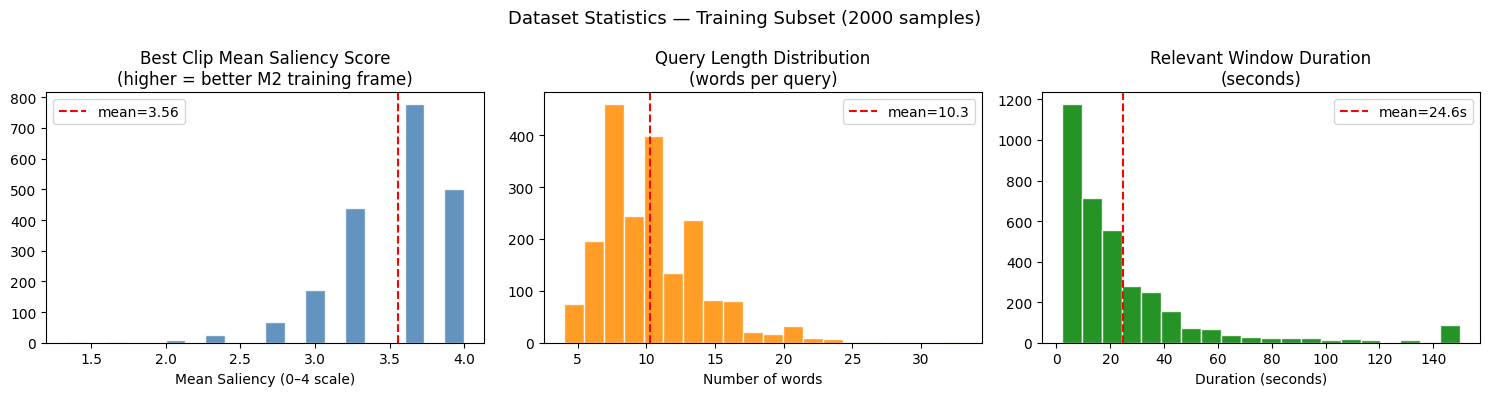

Mean saliency score  : 3.557 / 4.0
Mean query length    : 10.3 words
Mean window duration : 24.6 seconds


In [ ]:
import matplotlib.pyplot as plt

# ── 1. Saliency score distribution ──────────────────────────────────────────
saliency_vals = [r["mean_saliency"] for r in train_subset if r["mean_saliency"] is not None]

# ── 2. Query length distribution ────────────────────────────────────────────
query_lengths = [len(r["query"].split()) for r in train_subset]

# ── 3. Relevant window duration distribution ─────────────────────────────────
window_durations = []
for r in train_subset:
    for w in r["relevant_windows"]:
        window_durations.append(w[1] - w[0])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("Dataset Statistics — Training Subset (2000 samples)", fontsize=13)

axes[0].hist(saliency_vals, bins=20, color="steelblue", edgecolor="white", alpha=0.85)
axes[0].set_title("Best Clip Mean Saliency Score\n(higher = better M2 training frame)")
axes[0].set_xlabel("Mean Saliency (0–4 scale)")
axes[0].axvline(np.mean(saliency_vals), color="red", linestyle="--",
                label=f"mean={np.mean(saliency_vals):.2f}")
axes[0].legend()

axes[1].hist(query_lengths, bins=20, color="darkorange", edgecolor="white", alpha=0.85)
axes[1].set_title("Query Length Distribution\n(words per query)")
axes[1].set_xlabel("Number of words")
axes[1].axvline(np.mean(query_lengths), color="red", linestyle="--",
                label=f"mean={np.mean(query_lengths):.1f}")
axes[1].legend()

axes[2].hist(window_durations, bins=20, color="green", edgecolor="white", alpha=0.85)
axes[2].set_title("Relevant Window Duration\n(seconds)")
axes[2].set_xlabel("Duration (seconds)")
axes[2].axvline(np.mean(window_durations), color="red", linestyle="--",
                label=f"mean={np.mean(window_durations):.1f}s")
axes[2].legend()

plt.tight_layout()
plt.savefig(str(PROCESSED_DIR / "dataset_stats.png"), dpi=150, bbox_inches="tight")
plt.show()

print(f"Mean saliency score  : {np.mean(saliency_vals):.3f} / 4.0")
print(f"Mean query length    : {np.mean(query_lengths):.1f} words")
print(f"Mean window duration : {np.mean(window_durations):.1f} seconds")

In [ ]:
# ── Validate all required fields are present ─────────────────────────────────
required_m1 = {"qid","query","vid","youtube_id","seg_start","seg_end",
                "relevant_windows","relevant_clip_ids","duration"}
required_m2 = {"qid","frame_path","query","vid","best_timestamp","mean_saliency","clip_score"}

def validate_records(records, required_fields, name):
    issues = []
    for i, r in enumerate(records):
        missing = required_fields - set(r.keys())
        if missing:
            issues.append(f"  Record {i} (qid={r.get('qid','?')}) missing: {missing}")
    if issues:
        print(f"\n{name} — {len(issues)} issues found:")
        for issue in issues[:5]:
            print(issue)
    else:
        print(f"  {name} — ✓ all {len(records)} records valid")

print("Validation:")
validate_records(train_subset, required_m1, "M1 train")
validate_records(m2_pairs,     required_m2, "M2 pairs")
validate_records(val_proc,     required_m1 - {"relevant_clip_ids"}, "M1 val")

# Visualize Visualizee!!!

Loaded 1608 M2 samples


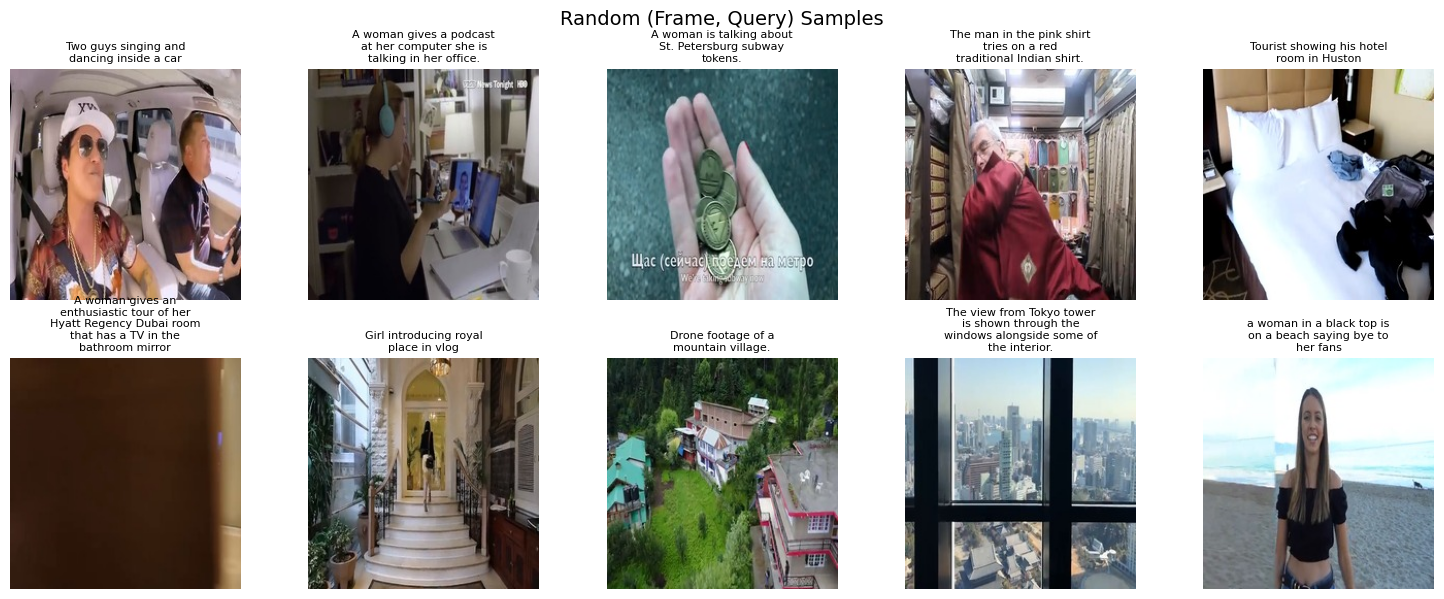

In [81]:
random.seed(82)
# ==============================
# PATHS
# ==============================
PROCESSED_DIR = Path("/content/drive/MyDrive/thumbnail_project/processed")
VIDEO_DIR     = Path("/content/drive/MyDrive/thumbnail_project/qvh_videos")

# ==============================
# LOAD DATA
# ==============================
def load_jsonl(path):
    data = []
    with open(path) as f:
        for line in f:
            data.append(json.loads(line))
    return data

m2_pairs = load_jsonl(PROCESSED_DIR / "m2_train_pairs.jsonl")

print(f"Loaded {len(m2_pairs)} M2 samples")

# ==============================
# 1. SHOW RANDOM FRAMES + QUERIES
# ==============================
import textwrap

def show_random_samples(n=10):
    samples = random.sample(m2_pairs, min(n, len(m2_pairs)))

    fig, axes = plt.subplots(2, 5, figsize=(15, 6))

    axes = axes.flatten()

    for i, s in enumerate(samples):
        img = Image.open(s["frame_path"])

        axes[i].imshow(img)
        axes[i].axis("off")

        title = s["query"]
        wrapped = "\n".join(textwrap.wrap(title, width=25))

        axes[i].set_title(wrapped, fontsize=8)


    plt.tight_layout(pad=0.6)
    plt.subplots_adjust(top=0.88)

    plt.suptitle("Random (Frame, Query) Samples", fontsize=14)

    plt.show()

def show_nice_sample(sample):
    import matplotlib.pyplot as plt
    import cv2
    from PIL import Image
    import textwrap

    video_path = VIDEO_DIR / f"{sample['vid']}.mp4"

    if not video_path.exists():
        print("Video not found")
        return

    # =========================
    # LOAD BEST FRAME
    # =========================
    img = Image.open(sample["frame_path"])

    # =========================
    # LOAD VIDEO CONTEXT
    # =========================
    cap = cv2.VideoCapture(str(video_path))
    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    best_frame = int(sample["best_timestamp"] * fps)

    offsets = [-8, -4, 0, 4, 8]
    frames = []

    for offset in offsets:
        target = best_frame + offset
        cap.set(cv2.CAP_PROP_POS_FRAMES, target)
        ret, frame = cap.read()

        if ret:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(frame)
        else:
            frames.append(None)

    cap.release()

    # =========================
    # FIGURE LAYOUT
    # =========================
    fig = plt.figure(figsize=(12, 6))

    # --- BEST FRAME ---
    ax_main = plt.subplot2grid((2, 5), (0, 1), colspan=3)
    ax_main.imshow(img)
    ax_main.axis("off")
    ax_main.set_title("BEST FRAME", fontsize=11, weight="bold")

    # --- QUERY ---
    query = "\n".join(textwrap.wrap(sample["query"], width=60))
    fig.text(0.5, 0.48, query, ha="center", fontsize=11)

    # --- CONTEXT FRAMES ---
    for i, f in enumerate(frames):
        ax = plt.subplot2grid((2, 5), (1, i))

        if f is not None:
            ax.imshow(f)
        else:
            ax.text(0.5, 0.5, "N/A", ha='center', va='center')

        ax.axis("off")

        if offsets[i] == 0:
            ax.set_title("BEST", color="red", fontsize=10, weight="bold")
        else:
            ax.set_title(f"{offsets[i]}", fontsize=9)

    plt.tight_layout()
    plt.subplots_adjust(hspace=0.3)
    plt.show()
# ==============================
# RUN EVERYTHING
# ==============================

# 1. random visualization
show_random_samples(10)

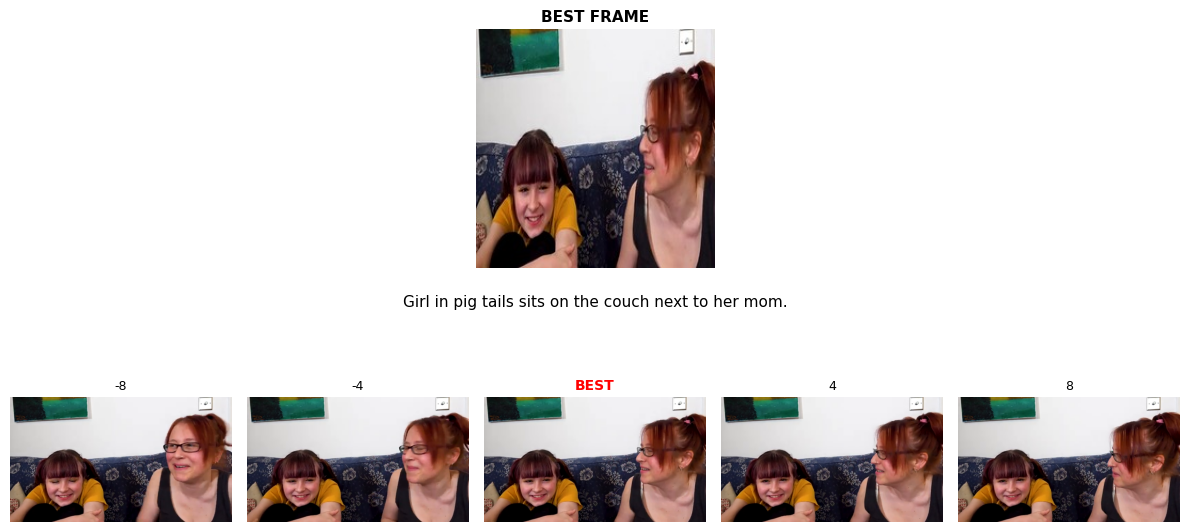

In [70]:
random.seed(87)
# 2. detailed example
sample = random.choice(m2_pairs)
# show_detailed_sample(sample)

# 3. video + frame validation
show_nice_sample(sample)

## DEBUG

Base video: gJFzRjGzxAg
Found 3 segments


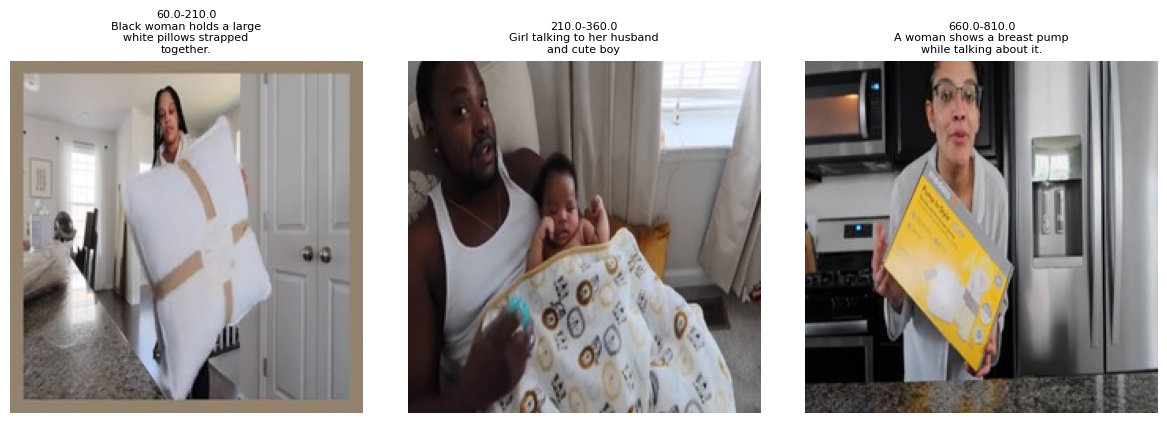

In [89]:
def debug_one_video(sample):
    import matplotlib.pyplot as plt
    from PIL import Image
    import textwrap

    def get_base_video_id(vid):
        return vid.rsplit("_", 2)[0]

    base_id = get_base_video_id(sample["vid"])

    related = [
        s for s in m2_pairs
        if get_base_video_id(s["vid"]) == base_id
    ]

    print(f"Base video: {base_id}")
    print(f"Found {len(related)} segments")

    # if only one segment
    if len(related) == 1:
        s = related[0]
        img = Image.open(s["frame_path"])

        plt.figure(figsize=(5,5))
        plt.imshow(img)
        plt.axis("off")

        q = "\n".join(textwrap.wrap(s["query"], width=40))

        plt.title(q, fontsize=11, pad=10)
        plt.tight_layout()
        plt.show()
        return

    # if more than one
    cols = min(5, len(related))
    rows = (len(related) + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(4*cols, 4*rows))
    axes = axes.flatten()

    for i, s in enumerate(related):
        img = Image.open(s["frame_path"])

        axes[i].imshow(img)
        axes[i].axis("off")

        q = "\n".join(textwrap.wrap(s["query"], width=30))

        start = s["vid"].split("_")[-2]
        end   = s["vid"].split("_")[-1]

        axes[i].set_title(f"{start}-{end}\n{q}", fontsize=8)

    for j in range(i+1, len(axes)):
        axes[j].axis("off")

    plt.tight_layout(pad=0.5)
    plt.show()

sample = random.choice(m2_pairs)
debug_one_video(sample)

# 12. CLIP Quality Analysis & Visual Dataset Audit

Four complementary visualisations that validate the semantic quality of the M2 dataset:

1. **CLIP score distribution** — dataset-level quality overview and filter threshold analysis.
2. **Best / Worst gallery** — highest vs lowest CLIP-scored pairs; confirms ranking is meaningful.
3. **Frame selection strip** — shows all candidate frames and their CLIP scores for individual samples.
4. **Cross-similarity matrix** — heatmap of frame × query CLIP similarities; diagonal dominance = good alignment.

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

# ── Reload m2_pairs fresh (catches clip_score even after Drive reload) ────────
m2_all = load_jsonl(PROCESSED_DIR / "m2_train_pairs.jsonl")
# Exclude None (fallback) entries from the distribution
scores = np.array([p["clip_score"] for p in m2_all
                   if p.get("clip_score") is not None])

THRESHOLD = 0.22   # empirical cutoff; below this = likely noisy pair

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle("CLIP Semantic Alignment — M2 Training Set", fontsize=13, y=1.01)

# ── Left: histogram ──────────────────────────────────────────────────────────
axes[0].hist(scores, bins=40, color="steelblue", edgecolor="white", alpha=0.85)
axes[0].axvline(THRESHOLD, color="crimson", lw=1.8, linestyle="--",
                label=f"threshold = {THRESHOLD}")
axes[0].axvline(scores.mean(), color="orange", lw=1.5, linestyle=":",
                label=f"mean = {scores.mean():.3f}")
axes[0].set_xlabel("CLIP cosine similarity (frame ↔ query)")
axes[0].set_ylabel("Count")
axes[0].set_title("Score Distribution")
axes[0].legend()

# ── Right: cumulative — how many pairs survive at each threshold ──────────────
thresholds = np.linspace(0.0, 0.35, 200)
survival   = [(scores >= t).sum() / len(scores) * 100 for t in thresholds]
axes[1].plot(thresholds, survival, color="steelblue", lw=2)
axes[1].axvline(THRESHOLD, color="crimson", lw=1.8, linestyle="--",
                label=f"threshold = {THRESHOLD}")
kept = (scores >= THRESHOLD).sum()
axes[1].scatter([THRESHOLD], [(scores >= THRESHOLD).sum() / len(scores) * 100],
                color="crimson", s=60, zorder=5,
                label=f"{kept} pairs kept ({100*kept/len(scores):.1f}%)")
axes[1].set_xlabel("CLIP score threshold")
axes[1].set_ylabel("% pairs retained")
axes[1].set_title("Survival Curve")
axes[1].legend()

plt.tight_layout()
plt.savefig(str(PROCESSED_DIR / "clip_score_distribution.png"), dpi=150, bbox_inches="tight")
plt.show()

print(f"Total M2 pairs       : {len(m2_all)}")
print(f"Mean CLIP score      : {scores.mean():.4f}")
print(f"Median CLIP score    : {np.median(scores):.4f}")
print(f"Pairs above {THRESHOLD}  : {kept}  ({100*kept/len(scores):.1f}%)")
print(f"Pairs below {THRESHOLD}  : {len(scores)-kept}  ({100*(len(scores)-kept)/len(scores):.1f}%)")


In [ ]:
import textwrap, random
from PIL import Image

# ── Best & Worst pairs — visual sanity check on CLIP ranking ─────────────────
def make_gallery(pairs, title, score_color):
    n   = len(pairs)
    cols = 4
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.5, rows * 3.8))
    axes = np.array(axes).flatten()
    fig.suptitle(title, fontsize=13, fontweight="bold", y=1.01)

    for i, p in enumerate(pairs):
        try:
            img = Image.open(p["frame_path"])
        except Exception:
            axes[i].axis("off")
            continue
        axes[i].imshow(img)
        axes[i].axis("off")
        q = "
".join(textwrap.wrap(p["query"], width=28))
        axes[i].set_title(
            f"{q}\n[score: {(p.get('clip_score') or 0):.3f}]",
            fontsize=7.5,
            color=score_color,
            pad=4,
        )

    for j in range(i + 1, len(axes)):
        axes[j].axis("off")

    plt.tight_layout(pad=0.8)
    return fig

# Sort descending; treat None (fallback) as 0 for ordering purposes
sorted_pairs = sorted(m2_all,
                      key=lambda x: x.get("clip_score") or 0,
                      reverse=True)
top_pairs    = sorted_pairs[:8]
bottom_pairs = sorted_pairs[-8:]

fig_top = make_gallery(top_pairs,    "Top 8 — Highest CLIP Score (best alignment)",  "darkgreen")
plt.savefig(str(PROCESSED_DIR / "gallery_top_clip.png"), dpi=150, bbox_inches="tight")
plt.show()

fig_bot = make_gallery(bottom_pairs, "Bottom 8 — Lowest CLIP Score (worst alignment)", "crimson")
plt.savefig(str(PROCESSED_DIR / "gallery_bottom_clip.png"), dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
# ── Frame Selection Verification Strip ────────────────────────────────────────
# For N random samples: show all candidate frames from the 2-sec clip
# with their per-frame CLIP scores. The selected (saved) frame is boxed in red.
# This validates that CLIP is picking visually meaningful frames, not just lucky ones.

N_SHOW       = 4     # samples to visualise
N_CANDS_SHOW = 8     # candidate frames per sample (re-extracted for display)

random.seed(99)
sample_pool = [p for p in m2_all if (p.get("clip_score") or 0) > 0.20]
show_samples = random.sample(sample_pool, min(N_SHOW, len(sample_pool)))

model_v, preprocess_v, device_v = _get_clip()

fig, big_axes = plt.subplots(N_SHOW, N_CANDS_SHOW + 1,
                              figsize=((N_CANDS_SHOW + 1) * 2.2, N_SHOW * 2.4))
fig.suptitle("Frame Selection Verification — Candidate Frames vs Selected Frame",
             fontsize=12, y=1.01)

for row, pair in enumerate(show_samples):
    vid_path = VIDEO_DIR / f"{pair['vid']}.mp4"
    cap      = cv2.VideoCapture(str(vid_path))
    fps_v    = cap.get(cv2.CAP_PROP_FPS) or 25.0
    cid      = int(pair["best_timestamp"] // 2)   # approximate clip id from saved ts
    start_f  = int(cid * 2 * fps_v)
    end_f    = int((cid * 2 + 2) * fps_v)
    pts      = np.linspace(start_f, max(end_f - 1, start_f), N_CANDS_SHOW, dtype=int)

    cand_pil, cand_ts = [], []
    for fn in pts:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(fn))
        ret, frm = cap.read()
        if ret:
            cand_pil.append(Image.fromarray(cv2.cvtColor(frm, cv2.COLOR_BGR2RGB)))
            cand_ts.append(int(fn) / fps_v)
    cap.release()

    if not cand_pil:
        continue

    with _clip_lock:
        cscores = clip_rank_frames(cand_pil, pair["query"], model_v, preprocess_v, device_v)

    best_i  = int(np.argmax(cscores)) if len(cscores) else 0

    # draw candidate frames
    for col, (pil_img, sc) in enumerate(zip(cand_pil, cscores)):
        ax = big_axes[row, col]
        ax.imshow(pil_img)
        ax.axis("off")
        ax.set_title(f"{sc:.3f}", fontsize=7,
                     color="crimson" if col == best_i else "gray")
        if col == best_i:
            for spine in ax.spines.values():
                spine.set_edgecolor("crimson")
                spine.set_linewidth(2.5)
                spine.set_visible(True)

    # last column: saved frame
    ax_saved = big_axes[row, N_CANDS_SHOW]
    try:
        ax_saved.imshow(Image.open(pair["frame_path"]))
    except Exception:
        pass
    ax_saved.axis("off")
    q_wrap = "\n".join(textwrap.wrap(pair["query"], width=20))
    ax_saved.set_title(f"SAVED\n{q_wrap}", fontsize=6.5, color="steelblue", fontweight="bold")

plt.tight_layout(pad=0.5)
plt.savefig(str(PROCESSED_DIR / "frame_selection_strip.png"), dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
# ── Cross-Similarity Matrix — Semantic Alignment Audit ────────────────────────
# Compute CLIP similarity between N frames and N queries.
# A well-aligned dataset shows diagonal dominance: each frame scores highest
# against its own query and lower against all others.
# Off-diagonal bright cells = ambiguous or mis-labelled pairs.

N_MATRIX = 12
random.seed(7)
mat_pool    = [p for p in m2_all if (p.get("clip_score") or 0) > 0.20]
mat_samples = random.sample(mat_pool, min(N_MATRIX, len(mat_pool)))

frames_mat, queries_mat = [], []
labels_short = []
for p in mat_samples:
    try:
        frames_mat.append(Image.open(p["frame_path"]))
        queries_mat.append(p["query"])
        labels_short.append("\n".join(textwrap.wrap(p["query"], width=18)))
    except Exception:
        pass

# Encode all frames
img_tensors = torch.stack([preprocess_v(f) for f in frames_mat]).to(device_v)
text_toks   = _clip_lib.tokenize(queries_mat, truncate=True).to(device_v)

with torch.no_grad():
    img_feats  = model_v.encode_image(img_tensors)
    txt_feats  = model_v.encode_text(text_toks)
    img_feats  = img_feats / img_feats.norm(dim=-1, keepdim=True)
    txt_feats  = txt_feats / txt_feats.norm(dim=-1, keepdim=True)
    sim_matrix = (img_feats @ txt_feats.T).cpu().numpy()   # (N_frames, N_queries)

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(sim_matrix, cmap="RdYlGn", aspect="auto", vmin=0.1, vmax=0.4)
plt.colorbar(im, ax=ax, label="CLIP cosine similarity")

ax.set_xticks(range(len(labels_short)))
ax.set_yticks(range(len(labels_short)))
ax.set_xticklabels(labels_short, fontsize=6, rotation=45, ha="right")
ax.set_yticklabels(labels_short, fontsize=6)
ax.set_xlabel("Query", fontsize=10)
ax.set_ylabel("Frame", fontsize=10)
ax.set_title(
    f"Frame × Query Cross-Similarity Matrix (N={len(frames_mat)})\n"
    "Diagonal should be brightest — off-diagonal bright = semantic confusion",
    fontsize=10
)

# Annotate diagonal
for i in range(len(frames_mat)):
    ax.add_patch(plt.Rectangle((i - 0.5, i - 0.5), 1, 1,
                                fill=False, edgecolor="black", lw=2))
    ax.text(i, i, f"{sim_matrix[i,i]:.2f}", ha="center", va="center",
            fontsize=7, fontweight="bold", color="black")

# Rank: for each row, what rank is the diagonal?
diag_ranks = []
for i in range(len(frames_mat)):
    row      = sim_matrix[i]
    rank     = sorted(row, reverse=True).index(row[i]) + 1
    diag_ranks.append(rank)

mean_rank = np.mean(diag_ranks)
rank1_pct = 100 * sum(r == 1 for r in diag_ranks) / len(diag_ranks)

plt.tight_layout()
plt.savefig(str(PROCESSED_DIR / "cross_similarity_matrix.png"), dpi=150, bbox_inches="tight")
plt.show()

print(f"Diagonal rank 1 (frame matches its own query best) : {rank1_pct:.0f}% of samples")
print(f"Mean diagonal rank                                  : {mean_rank:.2f}  (1.0 = perfect)")
print("\nPer-sample diagonal rank:")
for i, (p, rk) in enumerate(zip(mat_samples, diag_ranks)):
    flag = "✓" if rk == 1 else f"rank {rk}"
    print(f"  [{flag:6s}]  {p['query'][:60]}")


# 12. Final Directory Structure & What Goes Where

```
thumbnail_project/
moment_detr/
  data/
  highlight_train_release.jsonl   ← original, untouched
  highlight_val_release.jsonl
  highlight_test_release.jsonl
  subs_train.jsonl                ← ASR subtitles for M1 pretraining

processed/
  train_processed.jsonl             ← 2000 samples, enriched fields, frame_path
  train_full_processed.jsonl        ← all ~7000 train samples (no frames)
  val_processed.jsonl               ← official val, enriched
  test_processed.jsonl              ← official test, no saliency
  m2_train_pairs.jsonl              ← (frame_path, query) pairs for M2
  download_log.json                 ← which videos succeeded/failed
  dataset_stats.png                 ← statistics plot

qvh_videos/
  {vid}.mp4                         ← downloaded 150s clips
  ...

qvh_frames/
  {vid}.jpg                         ← extracted best frame (224×224) for M2
  ...
```

## Next steps
- **M1:** Load `train_processed.jsonl` + precomputed features → train Moment-DETR
- **M2:** Load `m2_train_pairs.jsonl` → train CLIP visual encoder + GPT-2 decoder
- **Evaluation:** Always use official `val_processed.jsonl` and `test_processed.jsonl`

**Limitation:**

* Modern video understanding systems face a dual challenge when generating textual queries from visual content. In our case, the **model is trained** on raw video **frames**, while in **real-world deployment it receives highly stylized thumbnails**. These thumbnails often include visual enhancements such as color adjustments, text overlays, zoomed-in faces, and other editing effects. This creates a domain gap between training data and inference inputs, which can negatively impact the model's ability to generalize.

(mafish kalam kefaya yawsaf (query) al thumbnial)
* At the same time, the system also suffers from **limitations in its language generation capabilities**. The model is trained on a relatively constrained set of queries, which restricts its vocabulary and expressive power. As a result, it may generate overly simple, repetitive, or even incoherent descriptions, especially when dealing with visually complex or unfamiliar thumbnails.

Combined Challenges
* **Domain Shift:**
A mismatch between clean training frames and real-world thumbnails leads to reduced performance.
* **Weak Visual-Text Alignment:**
Thumbnails may not perfectly represent the exact moment described by the query, introducing semantic noise.
* **Limited Vocabulary:**
The model struggles to describe diverse or complex scenes due to restricted language exposure.
* **Incoherent Generation:**
Outputs may be grammatically incorrect or semantically inconsistent, particularly under distribution shift.